# 13. Polymer dynamics

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 2, 4 and 5

A polymer in solution is a long chain that is constantly reshaped by thermal
motion. Pull it, and it relaxes back to a coil; put it in a flow, and it stretches.
The simplest model that captures this, due to Rouse (1953), treats the chain as
beads joined by springs. The springs are entropic: a piece of chain resists being
stretched because a stretched piece has fewer conformations. The beads feel the
friction of the solvent.

These are exactly the two functions of the Onsager principle: the free energy of
the springs and the friction of the beads. The Rayleighian gives the Rouse equation
in one line, and its normal modes give the relaxation times of the chain. Two new
things appear in this chapter. First, the chain fluctuates, and the Onsager
principle, which gives the motion of mean values, also gives the time correlations
of the fluctuations, through Onsager's regression hypothesis; we check this against
a Brownian dynamics simulation. Second, in a strong elongational flow the chain
stretches until its springs can stretch no further; the problem becomes nonlinear,
and the classic simplification, the dumbbell, turns out to be a one-parameter trial
function whose errors we can measure.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from matplotlib.patches import Circle, FancyArrowPatch
from scipy.integrate import solve_ivp
from scipy.linalg import eigh, expm

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

def laplacian(N):
    """Connectivity matrix of a linear chain of N beads: (L R)_n = 2R_n - R_{n+1} - R_{n-1}, ends with one neighbour."""
    return np.diag(np.r_[1.0, 2.0 * np.ones(N - 2), 1.0]) - np.eye(N, k=1) - np.eye(N, k=-1)

k_spring = 3.0          # units: b (rms bond length), kT, zeta b^2/kT; the spring constant is 3kT/b^2

## 13.1 The two functions of a chain

A chain of $N$ beads at positions $\mathbf R_n$, $n = 1, \ldots, N$. Each spring stands for a piece of
chain long enough to obey Gaussian statistics, with mean-square length $b^2$. Its
free energy is $\tfrac32k_BT\,r^2/b^2$ for an end-to-end vector $\mathbf r$, so

$$ A = \frac{k}{2}\sum_{n=1}^{N-1}\big(\mathbf R_{n+1} - \mathbf R_n\big)^2 , \qquad k = \frac{3k_BT}{b^2} . \tag{13.1} $$

Each bead moves through the solvent, which flows with the velocity $\mathbf v(\mathbf r)$, and
feels the friction $\zeta$ on its velocity relative to the solvent:

$$ \Phi = \frac{\zeta}{2}\sum_{n=1}^N\big(\dot{\mathbf R}_n - \mathbf v(\mathbf R_n)\big)^2 . \tag{13.2} $$

Minimising $R = \Phi + \dot A$ over the bead velocities gives the *Rouse equation*

$$ \zeta\big(\dot{\mathbf R}_n - \mathbf v(\mathbf R_n)\big) = k\big(\mathbf R_{n+1} - 2\mathbf R_n + \mathbf R_{n-1}\big) , \tag{13.3} $$

with only one neighbour for the two end beads. The cell below does it with sympy
for three beads in one dimension. Hydrodynamic interaction between the beads
(Chapter 2) is left out: each bead feels only the friction of the solvent. This is
the Rouse model; with hydrodynamic interaction it becomes the model of Zimm (1956).

*Units.* Lengths in $b$, energies in $k_BT$, times in $\zeta b^2/k_BT$. Then $k = 3$.

In [2]:
x1, x2, x3, v1, v2, v3, kk, zeta = sp.symbols("x1 x2 x3 v1 v2 v3 k zeta")
A = kk / 2 * ((x2 - x1) ** 2 + (x3 - x2) ** 2)
velocities = (v1, v2, v3)
Rayleighian = zeta / 2 * (v1**2 + v2**2 + v3**2) + sum(sp.diff(A, x) * v for x, v in zip((x1, x2, x3), velocities))
solution = sp.solve([sp.diff(Rayleighian, v) for v in velocities], velocities, dict=True)[0]
for v in velocities:
    print(f"zeta {v} =", sp.factor(zeta * solution[v]))

zeta v1 = -k*(x1 - x2)
zeta v2 = k*(x1 - 2*x2 + x3)
zeta v3 = k*(x2 - x3)


## 13.2 Normal modes

Without flow, Eq. (13.3) is linear: $\zeta\dot{\mathsf R} = -k\,\mathsf L\,\mathsf R$ for each Cartesian component, with the
connectivity matrix $\mathsf L$. Its eigenvectors are the *Rouse modes*, $\cos[p\pi(n - \tfrac12)/N]$,
and the rates are

$$ \lambda_p = \frac{4k}{\zeta}\,\sin^2\frac{p\pi}{2N} \simeq \frac{3\pi^2k_BT}{\zeta N^2b^2}\,p^2 , \qquad p = 0, 1, \ldots, N - 1 . \tag{13.4} $$

The mode $p = 0$ is the centre of mass, which does not relax: it diffuses with
$D_G = k_BT/N\zeta$. The slowest internal mode, $p = 1$, is a bending of the whole chain;
its time

$$ \tau_1 = \frac{1}{\lambda_1} \simeq \frac{\zeta N^2b^2}{3\pi^2k_BT} \tag{13.5} $$

is the *Rouse time*. It grows as $N^2$: a chain twice as long has twice as many beads
to drag, over twice the distance.

In [3]:
for N in (4, 16, 64):
    rates = np.linalg.eigvalsh(k_spring * laplacian(N))
    p = np.arange(N)
    print(f"N = {N:3d}: largest difference from Eq. (13.4), {np.max(np.abs(rates - 4 * k_spring * np.sin(p * np.pi / (2 * N)) ** 2)):.1e};"
          f"  tau_1 = {1 / rates[1]:8.2f},  continuum N^2/(3 pi^2) = {N**2 / (3 * np.pi**2):8.2f}")

N =   4: largest difference from Eq. (13.4), 3.6e-15;  tau_1 =     0.57,  continuum N^2/(3 pi^2) =     0.54
N =  16: largest difference from Eq. (13.4), 4.4e-15;  tau_1 =     8.67,  continuum N^2/(3 pi^2) =     8.65
N =  64: largest difference from Eq. (13.4), 5.3e-15;  tau_1 =   138.36,  continuum N^2/(3 pi^2) =   138.34


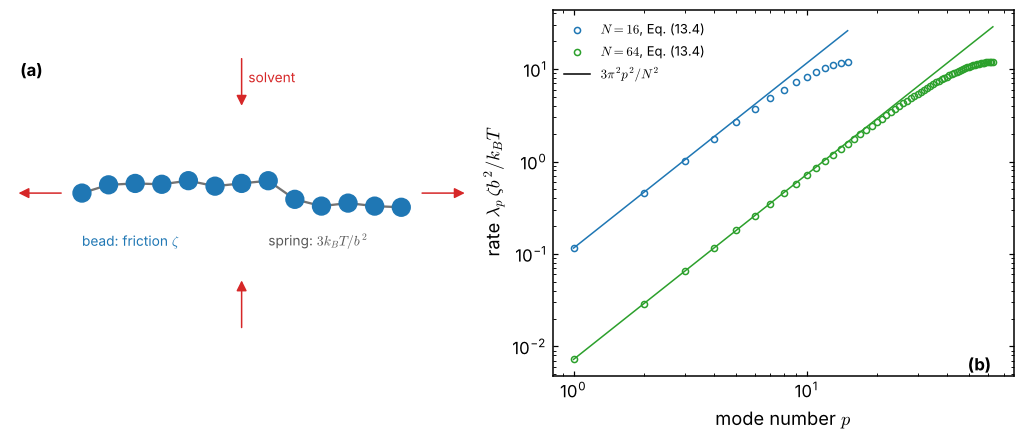

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))
ax1.set_xlim(-5.2, 5.2); ax1.set_ylim(-3.2, 3.2); ax1.set_aspect("equal"); ax1.axis("off")
rng_pic = np.random.default_rng(7)
xs = np.linspace(-3.6, 3.6, 13)
ys = 0.35 * np.sin(np.linspace(0, 5, 13)) + 0.15 * rng_pic.standard_normal(13)
ax1.plot(xs, ys, color="0.45", lw=1.5, zorder=1)
for xb, yb in zip(xs, ys):
    ax1.add_patch(Circle((xb, yb), 0.2, color="C0", zorder=2))
for sx in (-1, 1):
    ax1.add_patch(FancyArrowPatch((sx * 4.0, 0), (sx * 5.1, 0), arrowstyle="-|>", mutation_scale=14, color="C3"))
    ax1.add_patch(FancyArrowPatch((0, sx * 3.1), (0, sx * 1.9), arrowstyle="-|>", mutation_scale=14, color="C3"))
ax1.text(0.15, 2.5, "solvent", fontsize=9, color="C3")
ax1.text(-3.6, -1.2, r"bead: friction $\zeta$", fontsize=9, color="C0")
ax1.text(0.6, -1.2, r"spring: $3k_BT/b^2$", fontsize=9, color="0.35")
on.panel_label(ax1, "(a)", x=0.02, y=0.97)

for N, color in ((16, "C0"), (64, "C2")):
    rates = np.linalg.eigvalsh(k_spring * laplacian(N))[1:]
    p = np.arange(1, N)
    ax2.loglog(p, rates, "o", color=color, mfc="none", ms=4, label=f"$N = {N}$, Eq. (13.4)")
    ax2.loglog(p, 3 * np.pi**2 * p**2 / N**2, "-", color=color, lw=1)
ax2.plot([], [], "k-", lw=1, label=r"$3\pi^2p^2/N^2$")
ax2.set_xlabel("mode number $p$"); ax2.set_ylabel(r"rate $\lambda_p\,\zeta b^2/k_BT$")
ax2.legend(loc="upper left", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.9, y=0.06)
plt.show()

**Figure 13.1.** **(a)** The Rouse chain: beads with friction, joined by entropic
springs, here in an elongational flow (red arrows). **(b)** The relaxation rates of the
modes: exact (circles) and the continuum law $p^2$ (lines), which fails only for the
fastest modes, of the size of a few beads.

## 13.3 Fluctuations: Onsager's regression hypothesis

The Rouse equation gives the mean conformation. But a chain at rest is not still: it
fluctuates, and what experiments measure (by light scattering, by fluorescence, or
in the stress of a solution) are time correlations of these fluctuations. Onsager's
*regression hypothesis* connects the two: a fluctuation, once it has occurred,
decays on average by the same equation as a deviation produced by an external
cause. For a linear system it means

$$ \big\langle\mathsf R(t)\,\mathsf R(0)^{\mathsf T}\big\rangle = e^{-k\mathsf Lt/\zeta}\,\big\langle\mathsf R\,\mathsf R^{\mathsf T}\big\rangle , \tag{13.6} $$

where the equal-time correlations come from the free energy alone (equipartition,
$\langle\mathsf R\mathsf R^{\mathsf T}\rangle = k_BT\,(k\mathsf L)^{-1}$ in each direction, on the internal modes). Two
examples:

* the end-to-end vector $\mathbf u = \mathbf R_N - \mathbf R_1$, whose correlation function decays mostly with
  the Rouse time;
* the displacement of the middle bead, $g(t) = \langle[\mathbf R_m(t) - \mathbf R_m(0)]^2\rangle$, which grows as $t$ at short
  times, as $t^{1/2}$ at intermediate times (the bead drags a growing piece of chain
  along), and as $6D_Gt$ beyond the Rouse time.

For a solution of $\nu$ chains per unit volume, the same reasoning gives the stress
relaxation modulus of Rouse (1953),

$$ G(t) = \nu k_BT\sum_{p=1}^{N-1}e^{-2\lambda_pt} , \qquad \eta - \eta_s = \int_0^\infty G\,dt \simeq \frac{\nu\zeta N^2b^2}{36} . \tag{13.7} $$

*The check.* Equation (13.6) is a hypothesis, not a consequence of the Rayleighian.
To test it we simulate the chain with random forces: each bead obeys Eq. (13.3)
plus a random force whose strength, $\langle f^2\rangle \propto 2\zeta k_BT$, is fixed by the
fluctuation–dissipation theorem (`on.rouse_brownian_dynamics`). We start 2000
chains of 16 beads from equilibrium and average over many time origins.

In [5]:
N = 16
L16 = laplacian(N)
cov = np.linalg.pinv(k_spring * L16)                  # equilibrium covariance of the internal modes, per direction
rng = np.random.default_rng(0)
dt_bd, stride = 0.005, 20
times, ends, middle = on.rouse_brownian_dynamics(N, 2000, dt_bd, 150.0, stride, rng)
dt_rec = dt_bd * stride
lags = np.unique(np.round(np.logspace(0, np.log10(500), 40)).astype(int))
lag_t = np.r_[0.0, lags * dt_rec]
corr_bd = [np.mean(np.sum(ends * ends, axis=2))]
msd_bd = [0.0]
for lag in lags:
    corr_bd.append(np.mean(np.sum(ends[lag:] * ends[:-lag], axis=2)))
    msd_bd.append(np.mean(np.sum((middle[lag:] - middle[:-lag]) ** 2, axis=2)))
corr_bd, msd_bd = np.array(corr_bd), np.array(msd_bd)

d = np.zeros(N); d[-1], d[0] = 1.0, -1.0
m = N // 2
propagators = [expm(-k_spring * L16 * t) for t in lag_t]
corr_exact = np.array([3 * d @ P @ cov @ d for P in propagators])
msd_exact = np.array([3 * (2 * cov[m, m] - 2 * (P @ cov)[m, m]) + 6 * t / N for P, t in zip(propagators, lag_t)])
rates16 = np.linalg.eigvalsh(k_spring * L16)
print(f"Rouse time tau_1 = {1 / rates16[1]:.2f};  <u^2>: simulation {corr_bd[0]:.3f}, exact {corr_exact[0]:.3f}")
print("     t       <u(t).u(0)>: simulation   regression     MSD of the middle bead: simulation   exact")
for target in (0.0, 0.5, 2.0, 5.0, 10.0, 20.0, 40.0):
    i = int(np.argmin(np.abs(lag_t - target)))
    print(f"  {lag_t[i]:6.2f}            {corr_bd[i]:7.3f}          {corr_exact[i]:7.3f}                        {msd_bd[i]:7.3f}        {msd_exact[i]:7.3f}")
early = lag_t < 2.5 / rates16[1]
print(f"largest difference for t < 2.5 tau_1: correlation {np.max(np.abs(corr_bd - corr_exact)[early]) / corr_exact[0]:.3f} of <u^2>,"
      f" displacement {np.max(np.abs(msd_bd[1:] / msd_exact[1:] - 1)):.3f} (relative)")

Rouse time tau_1 = 8.67;  <u^2>: simulation 15.054, exact 15.000
     t       <u(t).u(0)>: simulation   regression     MSD of the middle bead: simulation   exact
    0.00             15.054           15.000                          0.000          0.000
    0.50             13.159           13.118                          1.332          1.319
    2.10             10.311           10.279                          2.821          2.804
    4.60              7.615            7.595                          4.207          4.182
   10.20              3.975            3.976                          6.492          6.478
   19.20              1.391            1.409                          9.892          9.880
   42.60              0.114            0.095                         18.553         18.662
largest difference for t < 2.5 tau_1: correlation 0.004 of <u^2>, displacement 0.022 (relative)


## 13.4 The dumbbell as a trial function

A popular simplification replaces the whole chain by a *dumbbell*: two beads and
one spring. In the language of this book it is a trial function with one
parameter. Let the chain be stretched uniformly, $\mathbf R_n = \mathbf R_G + s_n\mathbf X$, with
$s_n = (n - \tfrac{N+1}{2})/(N - 1)$ running from $-\tfrac12$ to $\tfrac12$, and $\mathbf X$ the end-to-end vector. Then

$$ A = \frac{k}{2(N - 1)}\,\mathbf X^2 , \qquad \Phi = \frac{\zeta}{2}\sum_ns_n^2\,\dot{\mathbf X}^2 = \frac{\zeta}{2}\,\frac{N(N + 1)}{12(N - 1)}\,\dot{\mathbf X}^2 , $$

and minimising the Rayleighian gives the relaxation rate

$$ \lambda_{\rm trial} = \frac{12k}{\zeta N(N + 1)} \;\to\; \frac{12}{\pi^2}\,\lambda_1 = 1.22\,\lambda_1 \quad\text{for long chains.} \tag{13.8} $$

As in Chapter 11 the trial rate is an upper bound. Adding odd powers of $s_n$ to the
trial ($\mathbf X_1s_n + \mathbf X_3s_n^3 + \ldots$) brings it down quickly, as the cell below shows.

In [6]:
def trial_rate(N, n_terms):
    s = (np.arange(N) - (N - 1) / 2) / (N - 1)
    B = np.array([s ** (2 * j + 1) for j in range(n_terms)]).T
    return eigh(B.T @ (k_spring * laplacian(N)) @ B, B.T @ B, eigvals_only=True)[0]

chain_lengths = np.array([8, 16, 32, 64, 128, 256, 512])
print("  N     lambda_1      trial/exact: 1 term    2 terms     3 terms")
trial_ratios = {}
for N_ in chain_lengths:
    exact = 4 * k_spring * np.sin(np.pi / (2 * N_)) ** 2
    trial_ratios[N_] = [trial_rate(N_, n) / exact for n in (1, 2, 3)]
    print(f"  {N_:4d}   {exact:.3e}        {trial_ratios[N_][0]:.5f}       {trial_ratios[N_][1]:.6f}    {trial_ratios[N_][2]:.8f}")
print(f"  12/pi^2 = {12 / np.pi**2:.5f}")

  N     lambda_1      trial/exact: 1 term    2 terms     3 terms
     8   4.567e-01        1.09476       1.000090    1.00000000
    16   1.153e-01        1.14802       1.000283    1.00000008
    32   2.889e-02        1.17996       1.000413    1.00000016
    64   7.227e-03        1.19739       1.000484    1.00000021
   128   1.807e-03        1.20649       1.000520    1.00000024
   256   4.518e-04        1.21114       1.000538    1.00000025
   512   1.129e-04        1.21349       1.000547    1.00000026
  12/pi^2 = 1.21585


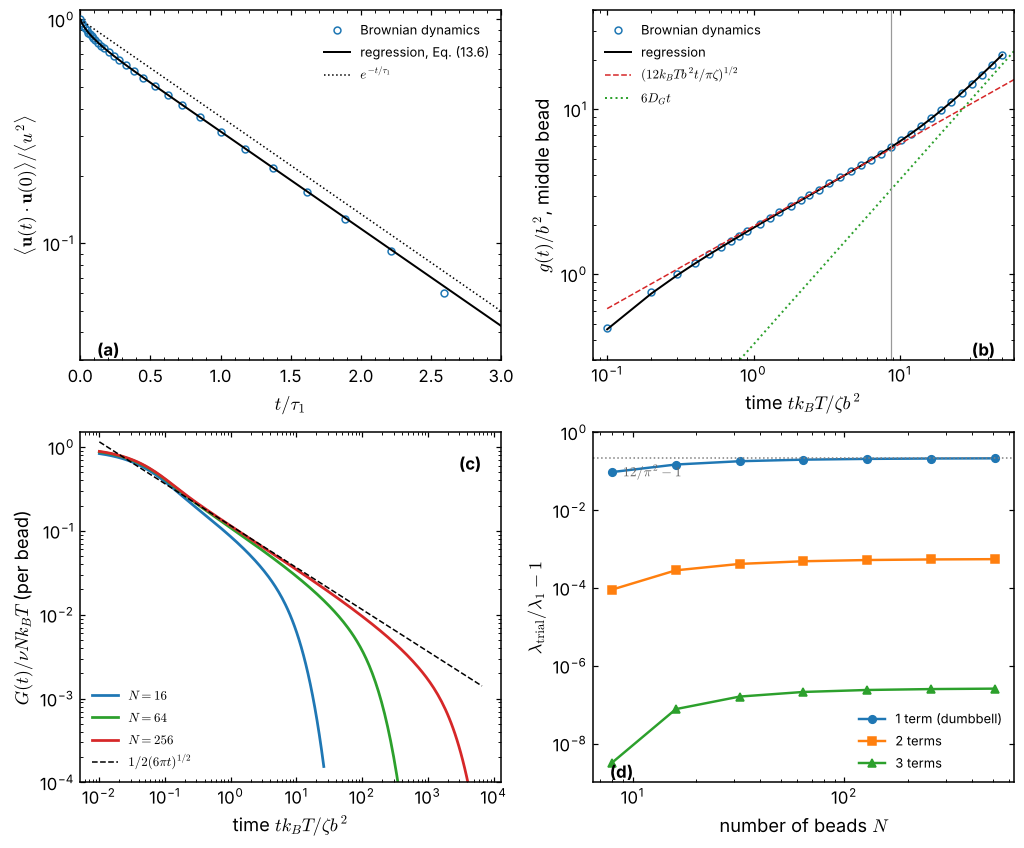

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))
tau1 = 1 / rates16[1]
ax = axes[0, 0]
ax.semilogy(lag_t / tau1, corr_bd / corr_bd[0], "C0o", mfc="none", ms=4.5, label="Brownian dynamics")
ax.semilogy(lag_t / tau1, corr_exact / corr_exact[0], "k-", lw=1.3, label="regression, Eq. (13.6)")
ax.semilogy(lag_t / tau1, np.exp(-lag_t / tau1), "k:", lw=1, label=r"$e^{-t/\tau_1}$")
ax.set_xlabel(r"$t/\tau_1$"); ax.set_ylabel(r"$\langle\mathbf{u}(t)\cdot\mathbf{u}(0)\rangle/\langle u^2\rangle$")
ax.set_xlim(0, 3); ax.set_ylim(0.03, 1.1)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(a)", x=0.04, y=0.06)

ax = axes[0, 1]
ax.loglog(lag_t[1:], msd_bd[1:], "C0o", mfc="none", ms=4.5, label="Brownian dynamics")
ax.loglog(lag_t[1:], msd_exact[1:], "k-", lw=1.3, label="regression")
tt = np.logspace(-1, 2.3, 50)
ax.loglog(tt, np.sqrt(12 * tt / np.pi), "C3--", lw=1, label=r"$(12k_BTb^2t/\pi\zeta)^{1/2}$")
ax.loglog(tt, 6 * tt / N, "C2:", lw=1.3, label=r"$6D_Gt$")
ax.axvline(tau1, color="0.6", lw=0.8)
ax.set_xlabel(r"time $tk_BT/\zeta b^2$"); ax.set_ylabel(r"$g(t)/b^2$, middle bead"); ax.set_xlim(0.08, 60); ax.set_ylim(0.3, 40)
ax.legend(loc="upper left", fontsize=8.5); on.panel_label(ax, "(b)", x=0.9, y=0.06)

ax = axes[1, 0]
for N_, color in ((16, "C0"), (64, "C2"), (256, "C3")):
    rates_ = np.linalg.eigvalsh(k_spring * laplacian(N_))[1:]
    tg = np.logspace(-2, np.log10(3 / rates_[0]), 200)
    ax.loglog(tg, [np.sum(np.exp(-2 * rates_ * t)) / N_ for t in tg], color=color, lw=1.8, label=f"$N = {N_}$")
ax.loglog(tg, 1 / (2 * np.sqrt(6 * np.pi * tg)), "k--", lw=1, label=r"$1/2(6\pi t)^{1/2}$")
ax.set_xlabel(r"time $tk_BT/\zeta b^2$"); ax.set_ylabel(r"$G(t)/\nu Nk_BT$ (per bead)"); ax.set_ylim(1e-4, 1.5)
ax.legend(loc="lower left", fontsize=8.5); on.panel_label(ax, "(c)", x=0.9, y=0.94)

ax = axes[1, 1]
for j, (marker, label) in enumerate((("o", "1 term (dumbbell)"), ("s", "2 terms"), ("^", "3 terms"))):
    ax.loglog(chain_lengths, [trial_ratios[N_][j] - 1 for N_ in chain_lengths], marker + "-", ms=5, label=label)
ax.axhline(12 / np.pi**2 - 1, color="0.5", ls=":", lw=1)
ax.text(9, 0.07, r"$12/\pi^2 - 1$", fontsize=9, color="0.4")
ax.set_xlabel("number of beads $N$"); ax.set_ylabel(r"$\lambda_{\rm trial}/\lambda_1 - 1$"); ax.set_ylim(1e-9, 1)
ax.legend(loc="lower right", fontsize=8.5); on.panel_label(ax, "(d)", x=0.04, y=0.06)
plt.show()

**Figure 13.2.** Fluctuations and relaxation of a Rouse chain ($N = 16$ in (a) and (b)).
**(a)** Correlation of the end-to-end vector: Brownian dynamics (circles) against the
regression hypothesis (line). **(b)** Mean-square displacement of the middle bead; the
vertical line marks the Rouse time. **(c)** Stress relaxation modulus per bead, Eq. (13.7),
for three chain lengths: all follow the same $t^{-1/2}$ law between the time of a bead and
the Rouse time of the chain.
**(d)** Error of the trial rates; the dumbbell is too fast by $12/\pi^2 - 1 = 22\,\%$ for long chains.

The simulation agrees with the regression hypothesis within its statistical
error: the mean-square end-to-end distance is 15.05 against 15, the correlation
function is within $0.004\langle u^2\rangle$ up to $2.5\tau_1$, and the displacement of the middle bead
within 2.2 % over the same range. The correlation decays slightly faster than $e^{-t/\tau_1}$ at first,
because the faster odd modes also contribute to the end-to-end vector (with weights
$8/\pi^2p^2$). The displacement shows the three regimes: free diffusion of the bead, the
$t^{1/2}$ law of a bead dragging a growing piece of chain (Exercise 2), and diffusion of
the whole chain beyond the Rouse time.

The trial functions behave as in Chapter 11. The dumbbell is too fast by 9 % for
8 beads and by 21 % for 512, approaching $12/\pi^2$. A uniformly stretched chain is not
the slowest mode: its ends move as much as its middle, while in the slowest mode the
middle is nearly at rest. A second term, $s_n^3$, bends the profile and brings the error
down to $5\times10^{-4}$; a third, to $3\times10^{-7}$.

## 13.5 Stretching in an elongational flow

In the uniaxial elongational flow $\mathbf v = \dot\varepsilon\,(x, -\tfrac12y, -\tfrac12z)$, with the chain centred at the
stagnation point, the $x$ component of Eq. (13.3) reads $\zeta\dot x_n = \zeta\dot\varepsilon x_n - k(\mathsf Lx)_n$: every
mode $p$ grows if $\dot\varepsilon > \lambda_p$. The chain therefore unwinds when $\dot\varepsilon$ exceeds the slowest rate
$\lambda_1 = 1/\tau_1$; with Gaussian springs it then stretches without limit. This is the
*coil–stretch transition* (de Gennes, 1974). With the Weissenberg number
$\mathrm{Wi} = \dot\varepsilon\tau_1$ the threshold is $\mathrm{Wi} = 1$. (Many authors use the relaxation time of the
stress, $\tau_1/2$, and put the threshold at $\tfrac12$.) The dumbbell trial puts it at
$\dot\varepsilon = \lambda_{\rm trial}$, about 20 % too late.

*Finite extensibility.* A real chain has a contour length. We give each spring the
free energy of a finitely extensible nonlinear elastic (FENE) spring of maximum
length $Q$,

$$ U(s) = -\frac{kQ^2}{2}\ln\Big(1 - \frac{s^2}{Q^2}\Big) , \qquad f(s) = U'(s) = \frac{ks}{1 - s^2/Q^2} , \tag{13.9} $$

which is Hookean for $s \ll Q$ and stiffens without bound as $s \to Q$. Now the problem
is nonlinear, and the stretched chain is no longer uniform: the friction of the
flow accumulates along the chain, so the tension is largest in the middle and zero
at the ends. In the steady state, $\zeta\dot\varepsilon x_n + T_n - T_{n-1} = 0$ with $T_n$ the tension of bond $n$
(`on.fene_chain_steady` solves it by marching the tension from one end).

The dumbbell trial, by contrast, assumes a uniform stretch $X/(N - 1)$ and gives
in closed form

$$ \frac{X}{(N - 1)Q} = \Big(1 - \frac{\lambda_{\rm trial}}{\dot\varepsilon}\Big)^{1/2} \qquad (\dot\varepsilon > \lambda_{\rm trial}) . \tag{13.10} $$

The cell below compares the two for a chain of 20 beads with $Q = 10b$, as for a
spring of 100 Kuhn segments.

In [8]:
N, Q = 20, 10.0
lam1 = 4 * k_spring * np.sin(np.pi / (2 * N)) ** 2
S = N * (N + 1) / (12 * (N - 1))
lam_trial = k_spring / (S * (N - 1))
x_max = (N - 1) * Q
print(f"N = {N}, Q = {Q:g}: lambda_1 = {lam1:.5f}, dumbbell threshold lambda_trial = {lam_trial:.5f} = {lam_trial / lam1:.3f} lambda_1")

Wi = np.concatenate((np.linspace(1.001, 1.3, 30), np.linspace(1.32, 4, 40), np.geomspace(4.2, 100, 30)))
full_ext, trial_ext = [], []
for w in Wi:
    x = on.fene_chain_steady(N, w * lam1, Q)
    full_ext.append(0.0 if x is None else (x[-1] - x[0]) / x_max)
    trial_ext.append(math.sqrt(max(1 - lam_trial / (w * lam1), 0.0)))
full_ext, trial_ext = np.array(full_ext), np.array(trial_ext)
print("    Wi      extension: full chain   dumbbell trial")
for w in (1.05, 1.1, 1.2, 1.5, 2, 3, 5, 10, 30, 100):
    i = np.argmin(np.abs(Wi - w))
    print(f"  {Wi[i]:6.2f}          {full_ext[i]:.4f}            {trial_ext[i]:.4f}")
above = Wi > 1.25
print(f"for Wi > 1.25 the dumbbell overestimates the extension by up to {np.max((trial_ext - full_ext)[above]):.3f}"
      f" (at Wi = {Wi[above][np.argmax((trial_ext - full_ext)[above])]:.2f})")

profiles = {w: on.fene_chain_steady(N, w * lam1, Q) for w in (1.5, 3.0, 10.0)}

def chain_rhs(t, x, rate):
    s = np.diff(x)
    T = k_spring * s / (1 - (s / Q) ** 2)
    F = np.zeros_like(x); F[:-1] += T; F[1:] -= T
    dx = rate * x + F
    return dx - dx.mean()            # the centre of mass sits at the stagnation point; remove numerical drift

rate = 3.0 * lam1
s_n = (np.arange(N) - (N - 1) / 2) / (N - 1)
t_tr = np.linspace(0, 12, 121) / lam1
full_tr = solve_ivp(chain_rhs, (0, t_tr[-1]), 0.01 * x_max * s_n, args=(rate,), t_eval=t_tr, method="BDF", rtol=1e-9, atol=1e-11)
full_tr = (full_tr.y[-1] - full_tr.y[0]) / x_max
dumbbell = solve_ivp(lambda t, X: [rate * X[0] - k_spring * (X[0] / (N - 1)) / (1 - (X[0] / x_max) ** 2) / S],
                     (0, t_tr[-1]), [0.01 * x_max], t_eval=t_tr, rtol=1e-10, atol=1e-12).y[0] / x_max
half = lambda e: t_tr[np.argmax(e > 0.5 * e[-1])] * lam1
print(f"Wi = 3 from 1 % extension: time to half the final extension, full chain {half(full_tr):.2f} tau_1, dumbbell {half(dumbbell):.2f} tau_1;"
      f" final {full_tr[-1]:.4f} and {dumbbell[-1]:.4f}")

N = 20, Q = 10: lambda_1 = 0.07387, dumbbell threshold lambda_trial = 0.08571 = 1.160 lambda_1


    Wi      extension: full chain   dumbbell trial
    1.05          0.1747            0.0000
    1.10          0.2428            0.0000
    1.20          0.3263            0.1748
    1.53          0.4938            0.4896
    2.01          0.6195            0.6495
    2.97          0.7429            0.7805
    5.23          0.8536            0.8820
   10.07          0.9242            0.9406
   30.05          0.9747            0.9805
  100.00          0.9924            0.9942
for Wi > 1.25 the dumbbell overestimates the extension by up to 0.038 (at Wi = 2.76)


Wi = 3 from 1 % extension: time to half the final extension, full chain 2.00 tau_1, dumbbell 2.10 tau_1; final 0.7455 and 0.7831


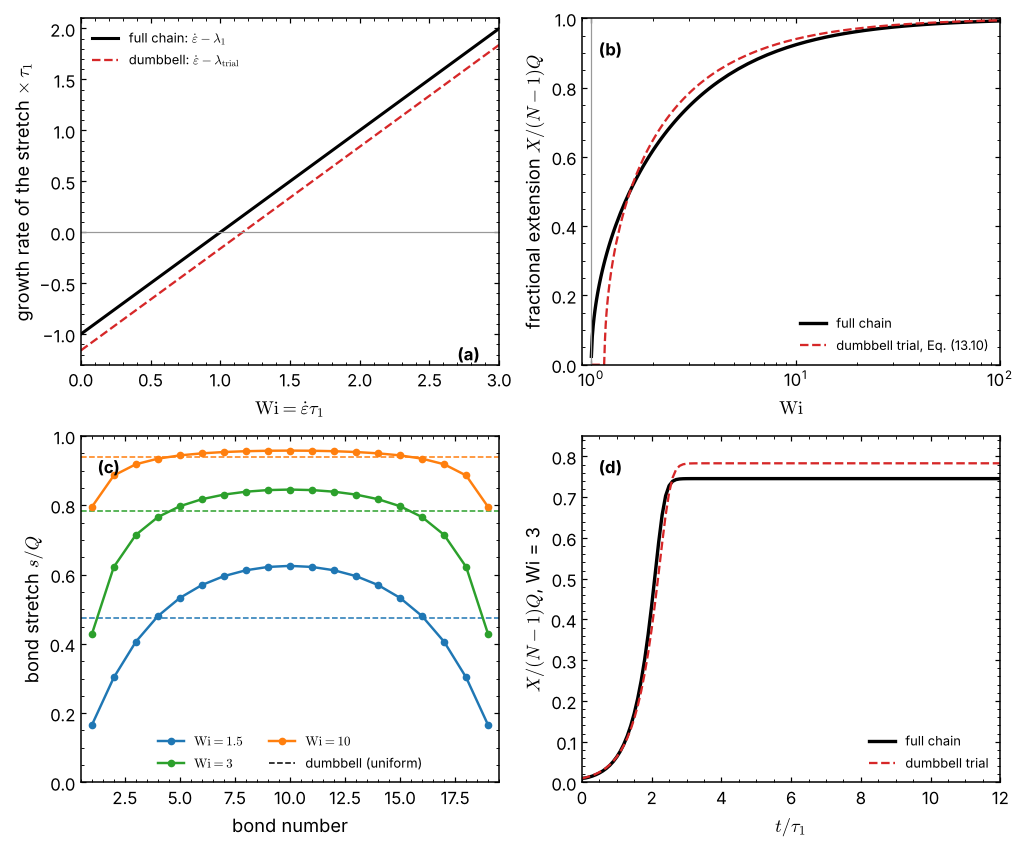

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))
ax = axes[0, 0]
w_lin = np.linspace(0, 3, 200)
ax.plot(w_lin, w_lin - 1, "k-", lw=2, label=r"full chain: $\dot\varepsilon - \lambda_1$")
ax.plot(w_lin, w_lin - lam_trial / lam1, "C3--", lw=1.5, label=r"dumbbell: $\dot\varepsilon - \lambda_{\rm trial}$")
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xlabel(r"$\mathrm{Wi} = \dot\varepsilon\tau_1$"); ax.set_ylabel(r"growth rate of the stretch $\times\,\tau_1$")
ax.set_xlim(0, 3); ax.set_ylim(-1.3, 2.1)
ax.legend(loc="upper left", fontsize=8.5); on.panel_label(ax, "(a)", x=0.9, y=0.06)

ax = axes[0, 1]
ax.semilogx(Wi, full_ext, "k-", lw=2.2, label="full chain")
ax.semilogx(Wi, trial_ext, "C3--", lw=1.5, label="dumbbell trial, Eq. (13.10)")
ax.axvline(1, color="0.6", lw=0.8)
ax.set_xlabel(r"$\mathrm{Wi}$"); ax.set_ylabel(r"fractional extension $X/(N-1)Q$"); ax.set_xlim(0.9, 100); ax.set_ylim(0, 1)
ax.legend(loc="lower right", fontsize=8.5); on.panel_label(ax, "(b)", x=0.04, y=0.94)

ax = axes[1, 0]
for w, color in zip(profiles, ("C0", "C2", "C1")):
    stretch = np.diff(profiles[w]) / Q
    bonds = np.arange(1, N)
    ax.plot(bonds, stretch, "o-", color=color, ms=4, label=rf"$\mathrm{{Wi}} = {w:g}$")
    ax.axhline(math.sqrt(1 - lam_trial / (w * lam1)), color=color, ls="--", lw=1)
ax.plot([], [], "k--", lw=1, label="dumbbell (uniform)")
ax.set_xlabel("bond number"); ax.set_ylabel("bond stretch $s/Q$"); ax.set_xlim(0.5, N - 0.5); ax.set_ylim(0, 1)
ax.legend(loc="lower center", fontsize=8.5, ncol=2); on.panel_label(ax, "(c)", x=0.04, y=0.94)

ax = axes[1, 1]
ax.plot(t_tr * lam1, full_tr, "k-", lw=2.2, label="full chain")
ax.plot(t_tr * lam1, dumbbell, "C3--", lw=1.5, label="dumbbell trial")
ax.set_xlabel(r"$t/\tau_1$"); ax.set_ylabel(r"$X/(N-1)Q$, Wi = 3"); ax.set_xlim(0, 12); ax.set_ylim(0, 0.85)
ax.legend(loc="lower right", fontsize=8.5); on.panel_label(ax, "(d)", x=0.04, y=0.94)
plt.show()

**Figure 13.3.** A chain in elongational flow ($N = 20$, $Q = 10b$). **(a)** Growth rate of a
small stretch: the dumbbell puts the coil–stretch threshold too late. **(b)** Steady
extension of a chain with FENE springs. **(c)** Stretch of the bonds along the chain at
three flow rates (circles) and the uniform stretch of the dumbbell (dashed). **(d)**
Stretching from an almost relaxed state at $\mathrm{Wi} = 3$.

The dumbbell is a fair description of a strongly stretched chain and a poor one
near the transition.

* *Threshold.* The full chain unwinds at $\mathrm{Wi} = 1$; the dumbbell only at $\mathrm{Wi} = 1.16$ for 20 beads
  (1.22 for long chains). In between, the full chain is already stretched to 17 % at
  $\mathrm{Wi} = 1.05$ and 24 % at $\mathrm{Wi} = 1.1$, while the dumbbell predicts no stretch at all.
* *Shape.* The tension is largest at the centre, so the middle bonds are stretched
  more than the ends: at $\mathrm{Wi} = 1.5$ the end bonds are at $0.17\,Q$ and the middle ones at
  $0.62\,Q$ (panel c). The uniform dumbbell stretches the ends too much and the middle
  too little, and overall it overestimates the extension, by up to 0.038 near $\mathrm{Wi} = 3$.
  At high flow rates both approach full extension.
* *Transient.* Starting from a nearly relaxed chain at $\mathrm{Wi} = 3$, both reach half their
  final extension after about two Rouse times (2.00 and 2.10): the stretching is
  driven by the slowest mode, which the dumbbell approximates well.

## 13.6 What to trust

* The Rouse model leaves out hydrodynamic interaction. In a dilute solution the
  solvent dragged by one bead moves the others, the chain moves more like a solid
  coil, and the times scale as $\eta_sR^3/k_BT$ (Zimm, 1956) rather than as $N^2$. In a melt of
  short chains hydrodynamic interaction is screened and the Rouse model applies.
* The flow calculations of Section 13.5 give the mean conformation and ignore the
  fluctuations about it. Near the coil–stretch threshold the fluctuations are large,
  and individual chains stretch at different times; above it, in a strongly
  stretched chain, the mean is a good description.
* Excluded volume and entanglements are left out. Long chains in a melt entangle,
  and their motion is reptation along a tube (Doi and Edwards, 1986).

## Summary

* A bead–spring chain has an entropic free energy, $\tfrac32k_BT/b^2$ per bond squared, and the
  friction of its beads. The Rayleighian gives the Rouse equation; its modes relax at
  rates $\propto p^2/N^2$, and the Rouse time grows as $N^2$.
* Onsager's regression hypothesis turns the equation for the mean into the time
  correlations of the fluctuations; a Brownian dynamics simulation agrees with it.
* The dumbbell is a one-parameter trial: a uniformly stretched chain. It relaxes
  22 % too fast and puts the coil–stretch transition too late; two trial functions are
  within a fraction of a per cent.
* With finite extensibility the stretched chain is not uniform: the tension is largest
  in the middle. The dumbbell overestimates the extension at high flow rates and
  misses the stretched state just above the threshold.

## Exercises

Sample solutions are in [`solutions/part3_soft_materials/13_solutions.ipynb`](../../solutions/part3_soft_materials/13_solutions.ipynb).

1. **The Rouse viscosity.** Show from Eq. (13.7) that for long chains
   $\eta - \eta_s \to \nu\zeta N^2b^2/36$, using $\sum1/p^2 = \pi^2/6$. Compute the sum exactly for $N = 4$ to 256 and
   compare. How does the viscosity of a solution at fixed mass concentration depend
   on $N$?
2. **The middle bead.** Using the continuum limit of the Rouse modes, show that the
   middle bead moves as $g(t) = (12k_BTb^2t/\pi\zeta)^{1/2}$ between the time of a single bead and the
   Rouse time. Check this against the exact discrete result for $N = 256$.
3. **Rouse or Zimm?** In the Zimm model a chain moves as a sphere of the size of the
   coil, $R \approx bN^{1/2}$, with the friction $6\pi\eta_sR$. Estimate its longest relaxation time from
   the time to diffuse its own size, and compare with the Rouse time (13.5) with
   $\zeta = 6\pi\eta_sb$. For which $N$ does the difference reach a factor of ten?
4. **Hysteresis.** De Gennes (1974) argued that the friction of a chain grows as it
   stretches, because the coil no longer shields its inner beads from the flow.
   Give the dumbbell of Section 13.5 the friction $\zeta_{\rm d}(X) = \zeta_{\rm d}(0)\,[1 + c\,X/X_{\max}]$ and find the steady
   states from the Rayleighian. Show that there is a range of flow rates with two
   stable states, coiled and stretched, and find how its width grows with $c$. Such
   conformation hysteresis was observed for DNA by Schroeder, Babcock, Shaqfeh and
   Chu (2003).

## Suggested references

* M. Doi and S. F. Edwards, *The Theory of Polymer Dynamics* (Oxford University Press, 1986).
* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* P. E. Rouse, "A theory of the linear viscoelastic properties of dilute solutions of coiling polymers", *J. Chem. Phys.* **21**, 1272 (1953).
* B. H. Zimm, "Dynamics of polymer molecules in dilute solution: viscoelasticity, flow birefringence and dielectric loss", *J. Chem. Phys.* **24**, 269 (1956).
* L. Onsager, "Reciprocal relations in irreversible processes. II", *Phys. Rev.* **38**, 2265 (1931).
* P. G. de Gennes, "Coil–stretch transition of dilute flexible polymers under ultrahigh velocity gradients", *J. Chem. Phys.* **60**, 5030 (1974).
* C. M. Schroeder, H. P. Babcock, E. S. G. Shaqfeh and S. Chu, "Observation of polymer conformation hysteresis in extensional flow", *Science* **301**, 1515 (2003).

---

**Previous:** [12. Phase separation](12_phase_separation.ipynb) &nbsp;·&nbsp; **Next:** [14. Nematic liquid crystals](14_nematic_liquid_crystals.ipynb)